=== PRELIMINARY GROUP 1 DATASET (S1-S13) ===
Physical Basis: 2.5 kg wet feed -> 0.5625 kg VS added | 50.0 m3 unventilated room assumption

=== TABLE 1: GAS BREAKDOWN AND LABORATORY SAFETY SCREENING ===
Scenario ID  Specific Yield (L/kgVS)  Total Biogas (L/run)  CH4 (L/run)  CO2 (L/run)  Raw H2S (ppmv)  Room H2S (ppm)  Batch Limit at 5ppm (kg)  Room CH4 (% LEL)
         S1                   258.71                 256.5        145.5        111.0          1065.0            5.46                      2.29              5.82
         S2                   270.00                 263.8        151.9        111.9          1065.0            5.62                      2.22              6.07
         S3                   285.05                 273.3        160.3        112.9          1065.0            5.82                      2.15              6.41
         S4                   296.88                 280.5        167.0        113.5          1065.0            5.97                      2.09            

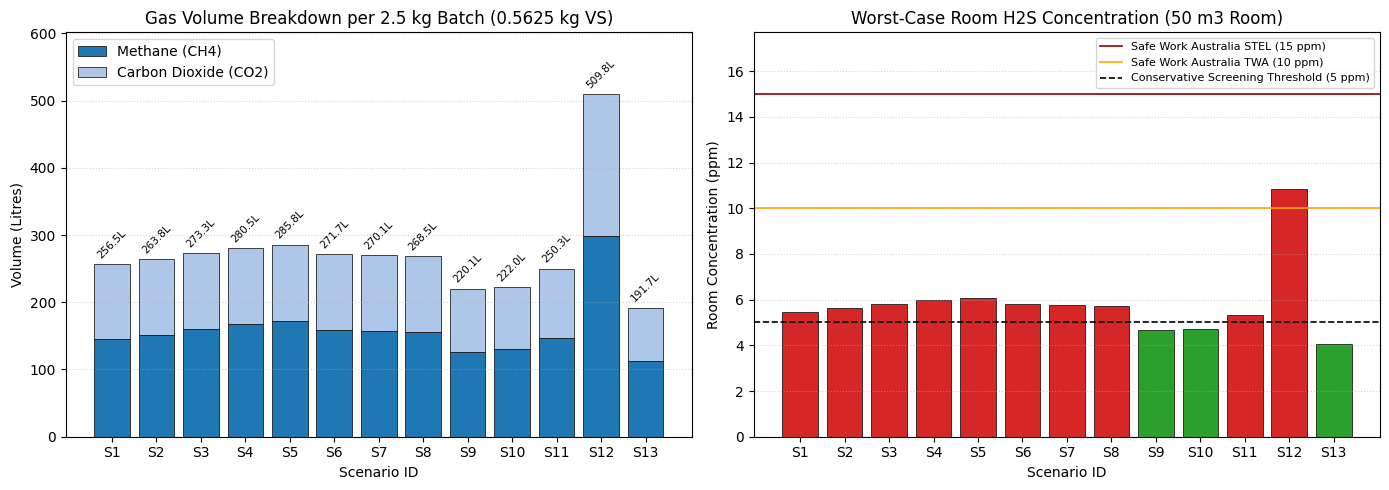

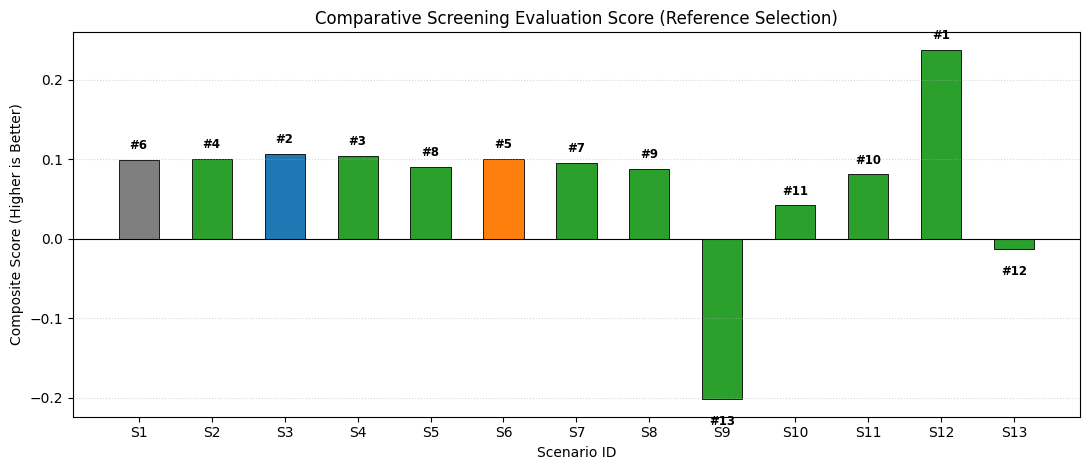

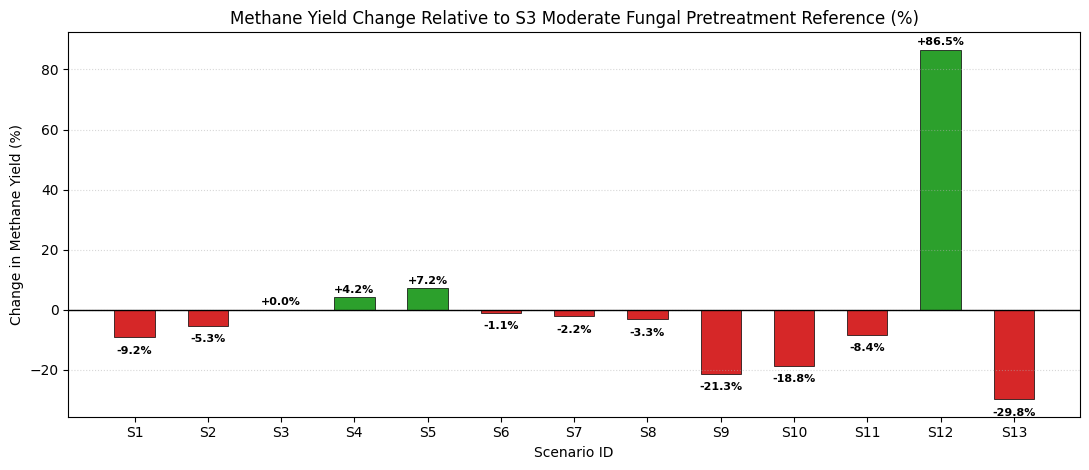

In [ ]:
# Standard libraries for calculations/data handling/plotting    
# numpy is used for mathematical operations
# pandas is used for organising outputs into clean tables
# matplotlib is used for generating comparison graphs for report deliverables
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# USER CONFIGURATION AND DATASET SELECTION
    # Dataset selection toggle: "group1" for S1-S13 or "zenodo" for S1-S9 benchmark
DATASET_CHOICE = "group1"

    # Prototype test batch and laboratory room dimensions
LAB_FEED_WET_KG = 2.5 # Prototype wet feedstock load per experimental run (Bita Meeting 8 & 10)
FEED_TS = 0.25 # Total solids fraction of food waste, 25% wet basis (He et al. 2024)
FEED_VS_TS = 0.90 # Volatile solids fraction of total solids, 90% of TS (He et al. 2024)
ROOM_VOLUME_M3 = 50.0 # Assumed enclosed laboratory room air volume in m3 (AS/NZS 2982 screening assumption)

    # Gas concentrations and regulatory thresholds
BIOGAS_H2S_PPM = 1065.0 # Raw biogas H2S concentration from literature (Tian et al. 2020)
H2S_REMOVAL_EFFICIENCY = 0.0 # Chemical trap efficiency: 0.0 = unscrubbed worst-case leak; 0.95 = active NaOH scrubber
H2S_TWA_LIMIT_PPM = 10.0 # Safe Work Australia 8-hour Time-Weighted Average workplace limit (Safe Work Australia 2025)
H2S_STEL_LIMIT_PPM = 15.0 # Safe Work Australia 15-minute Short-Term Exposure Limit (Safe Work Australia 2025)
H2S_SCREENING_LIMIT_PPM = 5.0 # Conservative project screening threshold (AWA review)
CO2_EXPOSURE_LIMIT_PPM = 5000.0 # Safe Work Australia 8-hour workplace exposure limit for CO2 (Safe Work Australia 2024)
CH4_LFL_PERCENT = 5.0 # Lower Flammability Limit of methane in air, 5% v/v (AS/NZS 60079.10.1)

    # Laboratory costing parameters
LAB_EQUIPMENT_CAPEX = 2002.86 # Total one-off lab equipment cost in AUD (Dimanthi Week 10)  
LAB_CONSUMABLES_RUN = 28.69 # Variable consumables cost per test run in AUD (Dimanthi Week 10)
AMORTISATION_RUNS = 20 # Planned number of experimental runs to amortise equipment (Bita Week 10)


# CONSTANTS FROM LITERATURE REVIEW
PH_OPT = 7.0 # Optimal pH from resource 1 (Modifications to ADM1)
PH_CRIT = 6.4 # Critical pH failure threshold from resource 3 (Methanogenic Inhibition TEA Analysis)
VFA_CRIT = 9.87 # Critical VFA threshold from resource 1 (Modifications to ADM1)
OLR_CRIT = 35.0 # Critical Organic Loading Rate from resource 1 (Modifications to ADM1)
FAN_CRIT = 0.0223 # Critical Free Ammonia Nitrogen limit from resource 1 (Modifications to ADM1)
LHV_CH4 = 35.8 # Energy constant for methane from formula sheet
FAILURE_DROP_PERCENT = 0.6426 # Productivity drop percentage during failure from resource 3 (Methanogenic Inhibition TEA Analysis)


# RISK AND STABILITY FORMULAS (FORMULAS 33, 34, 35, 36, 37)
    # each output returned capped between 0.0 and 1.0 to represent risk level
    # Formula 33: Calculate VFA risk based on critical limit of 9.87 g/L
def calculate_vfa_risk(current_vfa):
    risk = current_vfa / VFA_CRIT
    return min(max(risk, 0.0), 1.0)

    # Formula 34: Ammonia risk based on critical FAN limit
def calculate_ammonia_risk(current_fan):
    risk = current_fan / FAN_CRIT
    return min(max(risk, 0.0), 1.0)

    # Formula 35: pH risk based on deviation from optimal pH
def calculate_ph_risk(current_ph):
    risk = abs(current_ph - PH_OPT) / PH_OPT
    return min(max(risk, 0.0), 1.0)

    # Formula 36: Calculate Organic Loading Rate risk based on limit of 35.0
def calculate_olr_risk(current_olr):
    risk = current_olr / OLR_CRIT
    return min(max(risk, 0.0), 1.0)

    # Formula 37: Combined Stability Score
        # All four risks combined into a single 0 to 1 score
        # Using equal weights of 0.25 so total weight equals 1.0
def calculate_stability_score(r_vfa, r_nh3, r_ph, r_olr):
    w1, w2, w3, w4 = 0.25, 0.25, 0.25, 0.25
    total_penalty = (w1 * r_vfa) + (w2 * r_nh3) + (w3 * r_ph) + (w4 * r_olr)
    stability = 1.0 - total_penalty
    return max(0.0, min(stability, 1.0))

    # Min-max normalisation function for multi-criteria ranking
def min_max_scale(series):
    s_min = series.min()
    s_max = series.max()
    if s_max > s_min:
        return (series - s_min) / (s_max - s_min)
    return series * 0.0


# DATA LOADING: GROUP 1 OR ZENODO CSV DATASET
    # Ingestion of selected scenario summary dataset
if DATASET_CHOICE == "zenodo":
    csv_filename = "scenario_summary_results.csv"
    dataset_title = "Reference/Published Dataset (S1-S9, Zenodo Benchmark)"
else:
    csv_filename = "scenario_summary.csv"
    dataset_title = "Preliminary Group 1 Dataset (S1-S13)"

if os.path.exists(csv_filename):
    df_raw = pd.read_csv(csv_filename)
else:
    raise FileNotFoundError(f"Missing input dataset: {csv_filename}")

    # Automatic column name resolution between Group 1 and Zenodo formats
yield_col = "Specific Yield (L/kgVS)" if "Specific Yield (L/kgVS)" in df_raw.columns else "Methane yield practical (L/kgVS)"
ch4_fraction_col = "Predicted CH4 fraction in raw biogas (%)" if "Predicted CH4 fraction in raw biogas (%)" in df_raw.columns else "Methane purity (%)"
desc_col = "Scenario" if "Scenario" in df_raw.columns else "description"

    # Explicit scaling chain: wet mass (kg) -> TS (%) -> VS/TS (%) -> VS mass (kg)
vs_kg_run = LAB_FEED_WET_KG * FEED_TS * FEED_VS_TS # 2.5 kg * 0.25 * 0.90 = 0.5625 kg VS


# GAS BREAKDOWN AND SAFETY SCREENING
    # Scaling chain: specific yield (L/kg VS) * VS mass (kg) -> batch methane litres
ch4_litres_run = df_raw[yield_col] * vs_kg_run
ch4_fraction = df_raw[ch4_fraction_col] / 100.0
biogas_litres_run = ch4_litres_run / ch4_fraction
co2_litres_run = biogas_litres_run - ch4_litres_run

    # Theoretical unventilated room concentrations in a 50 m3 space (50,000 L air)
room_air_litres = ROOM_VOLUME_M3 * 1000.0
effective_h2s_biogas_ppm = BIOGAS_H2S_PPM * (1.0 - H2S_REMOVAL_EFFICIENCY)
h2s_litres_run = biogas_litres_run * (effective_h2s_biogas_ppm / 1e6)
room_h2s_ppm = (h2s_litres_run / room_air_litres) * 1e6

    # Room carbon dioxide concentration in ppm
room_co2_ppm = (co2_litres_run / room_air_litres) * 1e6

    # Room methane concentration and percentage of Lower Flammability Limit
room_ch4_pct = (ch4_litres_run / room_air_litres) * 100.0
room_ch4_lel_pct = (room_ch4_pct / CH4_LFL_PERCENT) * 100.0

    # Batch load limit in kg to remain below the 5.0 ppm conservative screening threshold
biogas_litres_per_kg_wet = biogas_litres_run / LAB_FEED_WET_KG
safe_batch_limit_kg = (H2S_SCREENING_LIMIT_PPM * room_air_litres) / (effective_h2s_biogas_ppm * biogas_litres_per_kg_wet) if effective_h2s_biogas_ppm > 0 else np.nan

    # Ratio of room H2S concentration relative to the 5.0 ppm screening threshold
h2s_risk_ratio = room_h2s_ppm / H2S_SCREENING_LIMIT_PPM


# ENERGY, COST, AND S3 COMPARATIVE METRICS
    # Parasitic process energy requirements in kWh/kg VS based on treatment duration
process_energy_lookup = {
    "S1": 0.30, "S2": 0.40, "S3": 0.50, "S4": 0.65, "S5": 0.91,
    "S6": 0.52, "S7": 0.55, "S8": 0.58, "S9": 0.39,
    "S10": 0.50, "S11": 0.50, "S12": 0.50, "S13": 0.50
}
process_energy_per_kg = df_raw["Scenario ID"].map(lambda x: process_energy_lookup.get(x, 0.50))

    # Gross methane energy and net energy per kg VS
gross_energy_kwh_kg = (df_raw[yield_col] * (LHV_CH4 / 3.6)) / 1000.0
net_energy_kwh_kg = gross_energy_kwh_kg - process_energy_per_kg

    # Unit cost per litre of methane produced with capital amortised over planned runs
equipment_cost_per_run = LAB_EQUIPMENT_CAPEX / float(AMORTISATION_RUNS)
total_run_cost_aud = LAB_CONSUMABLES_RUN + equipment_cost_per_run
cost_per_litre_ch4 = total_run_cost_aud / ch4_litres_run

    # Primary evaluation dataframe
df_group3 = pd.DataFrame({
    "Scenario ID": df_raw["Scenario ID"],
    "Description": df_raw[desc_col],
    "Specific Yield (L/kgVS)": df_raw[yield_col].round(2),
    "Total Biogas (L/run)": biogas_litres_run.round(1),
    "CH4 (L/run)": ch4_litres_run.round(1),
    "CO2 (L/run)": co2_litres_run.round(1),
    "Raw H2S (ppmv)": BIOGAS_H2S_PPM,
    "Room H2S (ppm)": room_h2s_ppm.round(2),
    "Batch Limit at 5ppm (kg)": safe_batch_limit_kg.round(2),
    "Room CO2 (ppm)": room_co2_ppm.round(1),
    "Room CH4 (% LEL)": room_ch4_lel_pct.round(2),
    "Stability Score": df_raw["Stability score"].round(3),
    "Net Energy (kWh/kg)": net_energy_kwh_kg.round(2),
    "Cost/L CH4 (AUD)": cost_per_litre_ch4.round(4)
})

    # Performance differences relative to S3 fungal reference condition (Formulas R10 & R11)
s3_yield = df_group3.loc[df_group3["Scenario ID"] == "S3", "Specific Yield (L/kgVS)"].values[0]
s3_stability = df_group3.loc[df_group3["Scenario ID"] == "S3", "Stability Score"].values[0]
s3_net_energy = df_group3.loc[df_group3["Scenario ID"] == "S3", "Net Energy (kWh/kg)"].values[0]

df_group3["% Delta CH4 vs S3"] = (((df_group3["Specific Yield (L/kgVS)"] - s3_yield) / s3_yield) * 100.0).round(2)
df_group3["Delta Stability vs S3"] = (df_group3["Stability Score"] - s3_stability).round(3)
df_group3["Delta Net Energy vs S3"] = (df_group3["Net Energy (kWh/kg)"] - s3_net_energy).round(2)


# COMPARATIVE SCREENING RANKING (TRANSPARENT 0-1 SCALE)
    # Standardised dimensionless indicators on a 0 to 1 interval
norm_energy = min_max_scale(df_group3["Net Energy (kWh/kg)"])
norm_stability = min_max_scale(df_group3["Stability Score"])
norm_gas_risk = min_max_scale(h2s_risk_ratio)
norm_cost = min_max_scale(df_group3["Cost/L CH4 (AUD)"])

    # Record transparent normalisation components in dataframe
df_group3["Norm Energy"] = norm_energy.round(3)
df_group3["Norm Stability"] = norm_stability.round(3)
df_group3["Norm Gas Risk"] = norm_gas_risk.round(3)
df_group3["Norm Cost"] = norm_cost.round(3)

    # Composite screening score combining energy, stability, gas risk, and unit cost
w_e, w_s, w_r, w_c = 0.25, 0.25, 0.25, 0.25
raw_screening_score = (
    (w_e * norm_energy)
    + (w_s * norm_stability)
    - (w_r * norm_gas_risk)
    - (w_c * norm_cost)
)

    # Ranks scenarios on unrounded float first to prevent artificial ties from decimal rounding
df_group3["Comparative Rank"] = raw_screening_score.rank(ascending=False, method="min").astype(int)
df_group3["Screening Score"] = raw_screening_score.round(3)

# TERMINAL EVALUATION OUTPUTS
print(f"=== {dataset_title.upper()} ===")
print(f"Physical Basis: {LAB_FEED_WET_KG} kg wet feed -> {vs_kg_run:.4f} kg VS added | {ROOM_VOLUME_M3} m3 unventilated room assumption\n")

print("=== TABLE 1: GAS BREAKDOWN AND LABORATORY SAFETY SCREENING ===")
table1_cols = [
    "Scenario ID", "Specific Yield (L/kgVS)", "Total Biogas (L/run)",
    "CH4 (L/run)", "CO2 (L/run)", "Raw H2S (ppmv)", "Room H2S (ppm)",
    "Batch Limit at 5ppm (kg)", "Room CH4 (% LEL)"
]
print(df_group3[table1_cols].to_string(index=False))

print("\n=== TABLE 2: S3 REFERENCE COMPARISONS (FORMULAS R10 & R11) ===")
table2_cols = [
    "Scenario ID", "Description", "Specific Yield (L/kgVS)",
    "% Delta CH4 vs S3", "Net Energy (kWh/kg)", "Delta Net Energy vs S3",
    "Stability Score"
]
print(df_group3[table2_cols].to_string(index=False))

print("\n=== TABLE 3: TRANSPARENT COMPARATIVE SCREENING RANKING ===")
table3_cols = [
    "Comparative Rank", "Scenario ID", "Norm Energy", "Norm Stability",
    "Norm Gas Risk", "Norm Cost", "Screening Score"
]
print(df_group3.sort_values("Comparative Rank")[table3_cols].to_string(index=False))


# DATA VISUALISATION: 3 SEPARATE FIGURES
scenarios = df_group3["Scenario ID"]

    # Figure 1 Panel 1: Biogas volume breakdown with total labels
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bars_ch4 = ax1.bar(scenarios, df_group3["CH4 (L/run)"], label="Methane (CH4)", color="#1f77b4", edgecolor="black", linewidth=0.5)
bars_co2 = ax1.bar(scenarios, df_group3["CO2 (L/run)"], bottom=df_group3["CH4 (L/run)"], label="Carbon Dioxide (CO2)", color="#aec7e8", edgecolor="black", linewidth=0.5)

    # Total biogas volume labels on top of stacked bars
for i, total in enumerate(df_group3["Total Biogas (L/run)"]):
    ax1.text(i, total + 6.0, f"{total:.1f}L", ha="center", va="bottom", fontsize=7.5, rotation=45)

ax1.set_title(f"Gas Volume Breakdown per {LAB_FEED_WET_KG} kg Batch ({vs_kg_run:.4f} kg VS)")
ax1.set_xlabel("Scenario ID")
ax1.set_ylabel("Volume (Litres)")
ax1.set_ylim(0, df_group3["Total Biogas (L/run)"].max() * 1.18)
ax1.grid(axis="y", linestyle=":", alpha=0.5)
ax1.legend(loc="upper left")

    # Figure 1 Panel 2: Room H2S concentration vs regulatory and project limits
h2s_colors = ["#d62728" if ppm > H2S_SCREENING_LIMIT_PPM else "#2ca02c" for ppm in df_group3["Room H2S (ppm)"]]
ax2.bar(scenarios, df_group3["Room H2S (ppm)"], color=h2s_colors, edgecolor="black", linewidth=0.5)
ax2.axhline(y=H2S_STEL_LIMIT_PPM, color="darkred", linestyle="-", linewidth=1.2, label=f"Safe Work Australia STEL ({H2S_STEL_LIMIT_PPM:.0f} ppm)")
ax2.axhline(y=H2S_TWA_LIMIT_PPM, color="orange", linestyle="-", linewidth=1.2, label=f"Safe Work Australia TWA ({H2S_TWA_LIMIT_PPM:.0f} ppm)")
ax2.axhline(y=H2S_SCREENING_LIMIT_PPM, color="black", linestyle="--", linewidth=1.2, label=f"Conservative Screening Threshold ({H2S_SCREENING_LIMIT_PPM:.0f} ppm)")

ax2.set_title(f"Worst-Case Room H2S Concentration ({ROOM_VOLUME_M3:.0f} m3 Room)")
ax2.set_xlabel("Scenario ID")
ax2.set_ylabel("Room Concentration (ppm)")
ax2.set_ylim(0, max(df_group3["Room H2S (ppm)"].max(), H2S_STEL_LIMIT_PPM) * 1.18)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

    # Figure 2: Comparative Screening Score ranking relative to S3
plt.figure(figsize=(11, 4.8))
bar_colors = ["#7f7f7f" if s == "S1" else "#1f77b4" if s == "S3" else "#ff7f0e" if s == "S6" else "#2ca02c" for s in scenarios]
bars = plt.bar(scenarios, df_group3["Screening Score"], color=bar_colors, edgecolor="black", linewidth=0.6, width=0.55)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Comparative Screening Evaluation Score (Reference Selection)")
plt.xlabel("Scenario ID")
plt.ylabel("Composite Score (Higher is Better)")
plt.grid(axis="y", linestyle=":", alpha=0.5)

for bar, rank in zip(bars, df_group3["Comparative Rank"]):
    y_val = bar.get_height()
    va_pos = "bottom" if y_val >= 0 else "top"
    y_offset = 0.01 if y_val >= 0 else -0.02
    plt.text(bar.get_x() + bar.get_width() / 2.0, y_val + y_offset, f"#{rank}", ha="center", va=va_pos, fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

    # Figure 3: Methane Yield Change relative to S3 Fungal Reference
plt.figure(figsize=(11, 4.8))
delta_ch4 = df_group3["% Delta CH4 vs S3"]
gain_loss_colors = ["#1f77b4" if s == "S3" else "#2ca02c" if val >= 0 else "#d62728" for s, val in zip(scenarios, delta_ch4)]
bars3 = plt.bar(scenarios, delta_ch4, color=gain_loss_colors, edgecolor="black", linewidth=0.5, width=0.55)
plt.axhline(0, color="black", linewidth=1.0)

for bar in bars3:
    height = bar.get_height()
    va_align = "bottom" if height >= 0 else "top"
    y_pos = height + 0.8 if height >= 0 else height - 2.8
    plt.text(bar.get_x() + bar.get_width() / 2.0, y_pos, f"{height:+.1f}%", ha="center", va=va_align, fontsize=8, fontweight="bold")

plt.title("Methane Yield Change Relative to S3 Moderate Fungal Pretreatment Reference (%)")
plt.xlabel("Scenario ID")
plt.ylabel("Change in Methane Yield (%)")
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()